# Bài thực hành 1: Python
Trong bài thực hành này, chúng ta sẽ xây dựng 1 mô hình đồ chơi (toy model) cho 1 đồ thị tính toán (computation graph). Thực hiện yêu cầu từng phần và kiểm tra đoạn mã mình viết bằng cách chạy các hàm test. Đọc file pdf đi kèm để hiểu rõ hơn về hướng dẫn của bài thực hành.

Đồ thị tính toán là một phần quan trọng của các thư viện machine learning. Nó biểu diễn các biểu thức toán học thành dạng đồ thị (tức là gồm đỉnh và cạnh) và tối ưu hoá bước truyền xuôi (forward pass) và truyền ngược (backward pass). Kiến thức đạo hàm căn bản là cần thiết cho bài tập này.

## Bắt đầu

Để vẽ minh hoạ đồ thị cho đẹp, cài graphviz.

In [ ]:
%pip install -q graphviz

Nếu gặp `ExecutableNotFound`, máy chưa có chương trình Graphviz:
- Colab/Ubuntu: chạy `!apt-get update -qq` rồi `!apt-get install -y graphviz` trong một ô riêng.
- macOS có Homebrew: chạy `brew install graphviz` trong Terminal.
- Windows: cài Graphviz và thêm thư mục `bin` vào PATH, rồi khởi động lại kernel.

Khi chưa có `dot`, hàm vẽ vẫn trả về object chứa mã DOT; các test tính toán vẫn chạy được.

In [ ]:
import math
from graphviz import Digraph
from graphviz.backend import ExecutableNotFound
from IPython.display import display

def assert_close(actual, expected, message="Giá trị"):
    print(f"  {message}: nhận {actual}, kì vọng {expected}")
    assert math.isclose(
        actual, expected, rel_tol=1e-7, abs_tol=1e-9
    ), f"{message} chưa đúng"

Chúng ta bắt đầu với việc xây dựng class `Value`. 1 đối tượng thuộc class `Value` được biểu diễn bằng 1 đỉnh (Node/Vertex) trong đồ thị tính toán. Các thuộc tính của `Value` gồm có:


*   Giá trị, hay dữ liệu (data)
*   Các đỉnh tổ tiên của nó
*   Phép toán (operator), có thể không có
*   Đạo hàm của hàm số tổng quát nhất (đích) theo đỉnh hiện tại (`grad`)
*   Đạo hàm của đỉnh hiện tại theo các đỉnh cha của nó (`local_grad`)

Đọc file pdf để hiểu thêm.



__VIẾT MÃ VÀO 2 CELL KẾ TIẾP:__

**ĐỌC HƯỚNG DẪN TRONG ĐỀ BÀI CÂU 1.1 - 1.6 VÀ VIẾT MÃ VÀO 2 CELL CODE BÊN DƯỚI. KHÔNG THAY ĐỔI NỘI DUNG CÁC HÀM TEST.**

In [ ]:

def as_value(value):
    pass

In [29]:
class Value:

    def __init__(self, data, parents=(), op="", label="", local_grads=()):
        self.data = data
        self.parents = tuple(parents)
        self.op = op
        self.label = label
        self.grad = 0.0
        self.local_grads = tuple(local_grads)
        if len(self.parents) != len(self.local_grads):
            raise ValueError("Mỗi vị trí đầu vào cần một đạo hàm cục bộ.")

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad}, label={self.label!r})"

    def __add__(self, other):
        pass
    def __sub__(self, other):
        pass

    def __mul__(self, other):
        pass





    def _backward(self):
        pass

    def backward(self):
        pass

## CÂU 1: CÁC PHÉP TOÁN CĂN BẢN
Hoàn thành yêu cầu các phần sau bằng cách viết thêm các hàm và phương thức (method) vào 2 cell code trên, rồi chạy các hàm test bên dưới để kiểm tra. Không thay đổi nội dung các hàm test trong các cell dưới từ câu 1.1 - 1.6.

### 1.1 Phép cộng
Class `Value` của chúng ta hiện chưa hỗ trợ toán tử +. Hãy nạp chồng toán tử + bằng cách hoàn thành phương thức sau vào class `Value`:
```python
def __add__(self, other):
```
Lưu ý:
* `label` không quá quan trọng, ta bỏ qua
* `grad` tạm thời bỏ qua
* `op là "+"`
* `data`, `parents`, và `local_grad` sẽ như thế nào?

Không thay đổi nội dung test, chạy `test_add()` bên dưới để kiểm tra.

In [ ]:
def test_add():
    print("Test 1.1: Phép cộng")

    try:
        a = Value(2, label="a")
        b = Value(3, label="b")

        cases = [
            ("a + b: hai Value khác nhau", b, 5),
            ("a + a: cùng một object", a, 4),
            ("a + 3: int bên phải", 3, 5),
            ("a + 0.5: float bên phải", 0.5, 2.5),
        ]

        for description, other, expected in cases:
            print(f"\n{description}")
            c = a + other

            assert isinstance(c, Value), "Kết quả phải là Value"
            assert_close(c.data, expected, "data")
            assert c.op == "+", "op phải là '+'"
            print("  op: PASS")

            assert len(c.parents) == 2, "Cần hai vị trí đầu vào"
            assert c.parents[0] is a, "parents[0] phải là a"

            if isinstance(other, Value):
                assert c.parents[1] is other, (
                    "parents[1] phải là đúng object đầu vào"
                )
            else:
                assert isinstance(c.parents[1], Value), (
                    "Số Python phải được chuyển thành Value"
                )
                assert_close(
                    c.parents[1].data, other, "Đầu vào thứ hai"
                )

            print("  parents: PASS")

            assert len(c.local_grads) == 2, "Cần hai đạo hàm cục bộ"
            assert_close(c.local_grads[0], 1, "local_grads[0]")
            assert_close(c.local_grads[1], 1, "local_grads[1]")

            print("\na + string: kiểu không hỗ trợ")
            try:
              a + "hello"
            except TypeError:
              print("  TypeError: PASS")
            else:
              raise AssertionError(
                  "Cộng với string phải báo TypeError"
                    )

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 1.1")
        return False

    print("\nPASS test 1.1")
    return True


test_add();

Test 1.1: Phép cộng

a + b: hai Value khác nhau
  data: nhận 5, kì vọng 5
  op: PASS
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận 1, kì vọng 1

a + string: kiểu không hỗ trợ
  TypeError: PASS

a + a: cùng một object
  data: nhận 4, kì vọng 4
  op: PASS
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận 1, kì vọng 1

a + string: kiểu không hỗ trợ
  TypeError: PASS

a + 3: int bên phải
  data: nhận 5, kì vọng 5
  op: PASS
  Đầu vào thứ hai: nhận 3, kì vọng 3
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận 1, kì vọng 1

a + string: kiểu không hỗ trợ
  TypeError: PASS

a + 0.5: float bên phải
  data: nhận 2.5, kì vọng 2.5
  op: PASS
  Đầu vào thứ hai: nhận 0.5, kì vọng 0.5
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận 1, kì vọng 1

a + string: kiểu không hỗ trợ
  TypeError: PASS

PASS test 1.1


### 1.2 Phép trừ
Cũng như phép cộng, hãy viết method cho class `Value`:
```python
def __sub__(self, other):
```
Lưu ý:



*   `op là "-"`
*   Bỏ qua `label` và `grad`, các thuộc tính còn lại sẽ như thế nào?

Không thay đổi nội dung test, chạy `test_sub()` để kiểm tra.






In [ ]:
def test_sub():
    print("Test 1.2: Phép trừ")

    try:
        a = Value(2, label="a")
        b = Value(3, label="b")

        cases = [
            ("a - b: hai Value khác nhau", b, -1),
            ("a - a: cùng một object", a, 0),
            ("a - 3: số int bên phải", 3, -1),
            ("a - 0.5: số float bên phải", 0.5, 1.5),
        ]

        for description, other, expected in cases:
            print(f"\n{description}")
            c = a - other

            assert isinstance(c, Value), "Kết quả phải là Value"
            assert_close(c.data, expected, "data")
            assert c.op == "-", "op phải là '-'"
            print("  op: PASS")

            assert len(c.parents) == 2, "Cần hai vị trí đầu vào"
            assert c.parents[0] is a, "parents[0] phải là a"

            if isinstance(other, Value):
                assert c.parents[1] is other, (
                    "parents[1] phải là đúng object đầu vào"
                )
            else:
                assert isinstance(c.parents[1], Value), (
                    "Số Python phải được chuyển thành Value"
                )
                assert_close(
                    c.parents[1].data, other, "Đầu vào thứ hai"
                )

            print("  parents: PASS")

            assert len(c.local_grads) == 2, "Cần hai đạo hàm cục bộ"
            assert_close(c.local_grads[0], 1, "local_grads[0]")
            assert_close(c.local_grads[1], -1, "local_grads[1]")

        print("\na - string: kiểu không hỗ trợ")
        try:
            a - "hello"
        except TypeError:
            print("  TypeError: PASS")
        else:
            raise AssertionError(
                "Trừ với string phải báo TypeError"
            )
    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 1.2")
        return False

    print("\nPASS test 1.2")
    return True


test_sub();

Test 1.2: Phép trừ

a - b: hai Value khác nhau
  data: nhận -1, kì vọng -1
  op: PASS
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận -1, kì vọng -1

a - a: cùng một object
  data: nhận 0, kì vọng 0
  op: PASS
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận -1, kì vọng -1

a - 3: số int bên phải
  data: nhận -1, kì vọng -1
  op: PASS
  Đầu vào thứ hai: nhận 3, kì vọng 3
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận -1, kì vọng -1

a - 0.5: số float bên phải
  data: nhận 1.5, kì vọng 1.5
  op: PASS
  Đầu vào thứ hai: nhận 0.5, kì vọng 0.5
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận -1, kì vọng -1

a - string: kiểu không hỗ trợ
  TypeError: PASS

PASS test 1.2


### 1.3 Phép nhân:
Cũng vậy, nạp chồng toán tử * (`op là "*"`) bằng cách hoàn thành method sau cho class `Value`:
```python
def __mul__(self, other):
```
Không thay đổi nội dung test, chạy `test_mul()` để kiểm tra.

In [ ]:
def test_mul():
    print("Test 1.3: Phép nhân")

    try:
        a = Value(-2, label="a")
        b = Value(3, label="b")

        # Mỗi dòng: mô tả, toán hạng phải, data, local_grads kì vọng.
        cases = [
            ("a * b: hai Value khác nhau", b, -6, (3, -2)),
            ("a * a: cùng một object", a, 4, (-2, -2)),
            ("a * 0: số int bên phải", 0, 0, (0, -2)),
            ("a * 0.5: số float bên phải", 0.5, -1, (0.5, -2)),
        ]

        for description, other, expected, expected_grads in cases:
            print(f"\n{description}")
            c = a * other

            assert isinstance(c, Value), "Kết quả phải là Value"
            assert_close(c.data, expected, "data")
            assert c.op == "*", "op phải là '*'"
            print("  op: PASS")

            assert len(c.parents) == 2, "Cần hai vị trí đầu vào"
            assert c.parents[0] is a, "parents[0] phải là a"

            if isinstance(other, Value):
                assert c.parents[1] is other, (
                    "parents[1] phải là đúng object đầu vào"
                )
            else:
                assert isinstance(c.parents[1], Value), (
                    "Số Python phải được chuyển thành Value"
                )
                assert_close(
                    c.parents[1].data, other, "Đầu vào thứ hai"
                )

            print("  parents: PASS")

            assert len(c.local_grads) == 2, "Cần hai đạo hàm cục bộ"
            assert_close(
                c.local_grads[0], expected_grads[0], "local_grads[0]"
            )
            assert_close(
                c.local_grads[1], expected_grads[1], "local_grads[1]"
            )

        print("\na * string: kiểu không hỗ trợ")
        try:
            a * "hello"
        except TypeError:
            print("  TypeError: PASS")
        else:
            raise AssertionError(
                "Nhân với string phải báo TypeError"
            )

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 1.3")
        return False

    print("\nPASS test 1.3")
    return True


test_mul();

Test 1.3: Phép nhân

a * b: hai Value khác nhau
  data: nhận -6, kì vọng -6
  op: PASS
  parents: PASS
  local_grads[0]: nhận 3, kì vọng 3
  local_grads[1]: nhận -2, kì vọng -2

a * a: cùng một object
  data: nhận 4, kì vọng 4
  op: PASS
  parents: PASS
  local_grads[0]: nhận -2, kì vọng -2
  local_grads[1]: nhận -2, kì vọng -2

a * 0: số int bên phải
  data: nhận 0, kì vọng 0
  op: PASS
  Đầu vào thứ hai: nhận 0, kì vọng 0
  parents: PASS
  local_grads[0]: nhận 0, kì vọng 0
  local_grads[1]: nhận -2, kì vọng -2

a * 0.5: số float bên phải
  data: nhận -1.0, kì vọng -1
  op: PASS
  Đầu vào thứ hai: nhận 0.5, kì vọng 0.5
  parents: PASS
  local_grads[0]: nhận 0.5, kì vọng 0.5
  local_grads[1]: nhận -2, kì vọng -2

a * string: kiểu không hỗ trợ
  TypeError: PASS

PASS test 1.3


### 1.4 Phép chia:
Tham khảo tài liệu Python: https://docs.python.org/3/reference/datamodel.html#emulating-numeric-types
Tìm cách nạp chồng phép chia.

Không thay đổi nội dung test, chạy `test_div()` để kiểm tra.

In [ ]:
def test_div():
    print("Test 1.4: Phép chia")

    try:
        a = Value(3, label="a")
        b = Value(-2, label="b")

        # Mỗi dòng: mô tả, toán hạng phải, data, local_grads kì vọng.
        cases = [
            ("a / b: hai Value khác nhau", b, -1.5, (-0.5, -0.75)),
            ("a / a: cùng một object", a, 1, (1 / 3, -1 / 3)),
            ("a / 2: số int bên phải", 2, 1.5, (0.5, -0.75)),
            ("a / 0.5: số float bên phải", 0.5, 6, (2, -12)),
        ]

        for description, other, expected, expected_grads in cases:
            print(f"\n{description}")
            c = a / other

            assert isinstance(c, Value), "Kết quả phải là Value"
            assert_close(c.data, expected, "data")
            assert c.op == "/", "op phải là '/'"
            print("  op: PASS")

            assert len(c.parents) == 2, "Cần hai vị trí đầu vào"
            assert c.parents[0] is a, "parents[0] phải là a"

            if isinstance(other, Value):
                assert c.parents[1] is other, (
                    "parents[1] phải là đúng object đầu vào"
                )
            else:
                assert isinstance(c.parents[1], Value), (
                    "Số Python phải được chuyển thành Value"
                )
                assert_close(
                    c.parents[1].data, other, "Đầu vào thứ hai"
                )

            print("  parents: PASS")

            assert len(c.local_grads) == 2, "Cần hai đạo hàm cục bộ"
            assert_close(
                c.local_grads[0], expected_grads[0], "local_grads[0]"
            )
            assert_close(
                c.local_grads[1], expected_grads[1], "local_grads[1]"
            )

        print("\na / string: kiểu không hỗ trợ")
        try:
            a / "hello"
        except TypeError:
            print("  TypeError: PASS")
        else:
            raise AssertionError(
                "Chia cho string phải báo TypeError"
            )

        zero_cases = [
            ("a / Value(0)", Value(0)),
            ("a / 0", 0),
        ]

        for description, zero in zero_cases:
            print(f"\n{description}")
            try:
                a / zero
            except ZeroDivisionError:
                print("  ZeroDivisionError: PASS")
            else:
                raise AssertionError(
                    "Chia cho 0 phải báo ZeroDivisionError"
                )

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 1.4")
        return False

    print("\nPASS test 1.4")
    return True


test_div();

Test 1.4: Phép chia

a / b: hai Value khác nhau
  data: nhận -1.5, kì vọng -1.5
  op: PASS
  parents: PASS
  local_grads[0]: nhận -0.5, kì vọng -0.5
  local_grads[1]: nhận -0.75, kì vọng -0.75

a / a: cùng một object
  data: nhận 1.0, kì vọng 1
  op: PASS
  parents: PASS
  local_grads[0]: nhận 0.3333333333333333, kì vọng 0.3333333333333333
  local_grads[1]: nhận -0.3333333333333333, kì vọng -0.3333333333333333

a / 2: số int bên phải
  data: nhận 1.5, kì vọng 1.5
  op: PASS
  Đầu vào thứ hai: nhận 2, kì vọng 2
  parents: PASS
  local_grads[0]: nhận 0.5, kì vọng 0.5
  local_grads[1]: nhận -0.75, kì vọng -0.75

a / 0.5: số float bên phải
  data: nhận 6.0, kì vọng 6
  op: PASS
  Đầu vào thứ hai: nhận 0.5, kì vọng 0.5
  parents: PASS
  local_grads[0]: nhận 2.0, kì vọng 2
  local_grads[1]: nhận -12.0, kì vọng -12

a / string: kiểu không hỗ trợ
  TypeError: PASS

a / Value(0)
  ZeroDivisionError: PASS

a / 0
  ZeroDivisionError: PASS

PASS test 1.4


### 1.5 Phép luỹ thừa:
Tìm trong tài liệu ở 1.4, tìm cách nạp chồng phép luỹ thừa.

Không thay đổi nội dung test, chạy `test_power()` để kiểm tra.

In [ ]:
def test_power():
    print("Test 1.5: Luỹ thừa")

    try:
        # Mô tả, cơ số, số mũ, data và local_grad kì vọng.
        cases = [
            ("Số mũ nguyên dương", 3, 2, 9, 6),
            ("Cơ số âm", -2, 3, -8, 12),
            ("Số mũ bằng 1", 3, 1, 3, 1),
            ("Số mũ bằng 0", 3, 0, 1, 0),
            ("Số mũ nguyên âm", 2, -2, 0.25, -0.25),
            ("Số mũ thực", 4, 0.5, 2, 0.25),
            ("Cơ số bằng 0", 0, 2, 0, 0),
        ]

        for description, base, exponent, expected, expected_grad in cases:
            print(f"\n{description}: Value({base}) ** {exponent}")
            a = Value(base, label="a")
            c = a ** exponent

            assert isinstance(c, Value), "Kết quả phải là Value"
            assert_close(c.data, expected, "data")
            assert c.op == f"**{exponent}", (
                f"op phải là '**{exponent}'"
            )
            print("  op: PASS")

            assert len(c.parents) == 1, "Chỉ có một đầu vào Value"
            assert c.parents[0] is a, "parents[0] phải là a"
            print("  parents: PASS")

            assert len(c.local_grads) == 1, (
                "Cần một đạo hàm cục bộ theo cơ số"
            )
            assert_close(
                c.local_grads[0], expected_grad, "local_grads[0]"
            )

        a = Value(2)

        for description, exponent in [
            ("Số mũ là string", "hello"),
            ("Số mũ là Value", Value(3)),
        ]:
            print(f"\n{description}: chưa hỗ trợ")
            try:
                a ** exponent
            except TypeError:
                print("  TypeError: PASS")
            else:
                raise AssertionError(
                    "Số mũ không hỗ trợ phải báo TypeError"
                )

        print("\nValue(0) ** -1")
        try:
            Value(0) ** -1
        except ZeroDivisionError:
            print("  ZeroDivisionError: PASS")
        else:
            raise AssertionError(
                "Cơ số 0 với số mũ âm phải báo ZeroDivisionError"
            )

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 1.5")
        return False

    print("\nPASS test 1.5")
    return True


test_power();

Test 1.5: Luỹ thừa

Số mũ nguyên dương: Value(3) ** 2
  data: nhận 9, kì vọng 9
  op: PASS
  parents: PASS
  local_grads[0]: nhận 6, kì vọng 6

Cơ số âm: Value(-2) ** 3
  data: nhận -8, kì vọng -8
  op: PASS
  parents: PASS
  local_grads[0]: nhận 12, kì vọng 12

Số mũ bằng 1: Value(3) ** 1
  data: nhận 3, kì vọng 3
  op: PASS
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1

Số mũ bằng 0: Value(3) ** 0
  data: nhận 1, kì vọng 1
  op: PASS
  parents: PASS
  local_grads[0]: nhận 0.0, kì vọng 0

Số mũ nguyên âm: Value(2) ** -2
  data: nhận 0.25, kì vọng 0.25
  op: PASS
  parents: PASS
  local_grads[0]: nhận -0.25, kì vọng -0.25

Số mũ thực: Value(4) ** 0.5
  data: nhận 2.0, kì vọng 2
  op: PASS
  parents: PASS
  local_grads[0]: nhận 0.25, kì vọng 0.25

Cơ số bằng 0: Value(0) ** 2
  data: nhận 0, kì vọng 0
  op: PASS
  parents: PASS
  local_grads[0]: nhận 0, kì vọng 0

Số mũ là string: chưa hỗ trợ
  TypeError: PASS

Số mũ là Value: chưa hỗ trợ
  TypeError: PASS

Value(0) ** -1
  ZeroDiv

### 1.6 Phép cộng, trừ, nhân, chia khi số hạng bên trái không phải class `Value` (`int`, `float`):
Nếu ta có `a = Value(2)`, `2 + a` vẫn chưa được giải quyết. Tìm trong tài liệu ở 1.4 cách nạp chồng các phép cộng trừ nhân chia khi số hạng bên trái không phải class `Value`, còn đối tượng `Value` của chúng ta nằm bên phải. Viết 4 method cho class `Value`.

Không thay đổi nội dung test, chạy `test_reflected()` để kiểm tra.


In [30]:
def test_reflected():
    print("Test 1.6: Các phép toán với số Python bên trái")

    try:
        a = Value(2, label="a")

        for number in (3, 0.5):
            cases = [
                ("+", number + a, number + 2, (1, 1), True),
                ("-", number - a, number - 2, (1, -1), False),
                ("*", number * a, number * 2, (2, number), True),
                ("/", number / a, number / 2,
                 (0.5, -number / 4), False),
            ]

            for symbol, c, expected, expected_grads, commutative in cases:
                print(f"\n{number} {symbol} a: số {type(number).__name__} bên trái")

                assert isinstance(c, Value), "Kết quả phải là Value"
                assert_close(c.data, expected, "data")
                assert c.op == symbol, f"op phải là '{symbol}'"
                print("  op: PASS")

                assert len(c.parents) == 2, "Cần hai vị trí đầu vào"
                assert len(c.local_grads) == 2, "Cần hai đạo hàm cục bộ"

                if c.parents[1] is a:
                    number_node = c.parents[0]
                    grads = expected_grads
                elif commutative and c.parents[0] is a:
                    number_node = c.parents[1]
                    grads = expected_grads[::-1]
                else:
                    raise AssertionError(
                        "parents không giữ đúng object a hoặc sai thứ tự"
                    )

                assert isinstance(number_node, Value), (
                    "Số Python phải được chuyển thành Value"
                )
                assert number_node is not a, "Hai đầu vào phải khác object"
                assert_close(number_node.data, number, "Đầu vào số Python")
                print("  parents: PASS")

                assert_close(c.local_grads[0], grads[0], "local_grads[0]")
                assert_close(c.local_grads[1], grads[1], "local_grads[1]")

        print("\n3 / Value(0)")
        try:
            3 / Value(0)
        except ZeroDivisionError:
            print("  ZeroDivisionError: PASS")
        else:
            raise AssertionError(
                "Chia cho 0 phải báo ZeroDivisionError"
            )

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 1.6")
        return False

    print("\nPASS test 1.6")
    return True


test_reflected();

Test 1.6: Các phép toán với số Python bên trái

3 + a: số int bên trái
  data: nhận 5, kì vọng 5
  op: PASS
  Đầu vào số Python: nhận 3, kì vọng 3
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận 1, kì vọng 1

3 - a: số int bên trái
  data: nhận 1, kì vọng 1
  op: PASS
  Đầu vào số Python: nhận 3, kì vọng 3
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: nhận -1, kì vọng -1

3 * a: số int bên trái
  data: nhận 6, kì vọng 6
  op: PASS
  Đầu vào số Python: nhận 3, kì vọng 3
  parents: PASS
  local_grads[0]: nhận 3, kì vọng 3
  local_grads[1]: nhận 2, kì vọng 2

3 / a: số int bên trái
  data: nhận 1.5, kì vọng 1.5
  op: PASS
  Đầu vào số Python: nhận 3, kì vọng 3
  parents: PASS
  local_grads[0]: nhận 0.5, kì vọng 0.5
  local_grads[1]: nhận -0.75, kì vọng -0.75

0.5 + a: số float bên trái
  data: nhận 2.5, kì vọng 2.5
  op: PASS
  Đầu vào số Python: nhận 0.5, kì vọng 0.5
  parents: PASS
  local_grads[0]: nhận 1, kì vọng 1
  local_grads[1]: n

# CÂU 2: DUYỆT VÀ VẼ ĐỒ THỊ
**CÁC HÀM VẼ ĐỒ THỊ DƯỚI ĐÂY ĐƯỢC CUNG CẤP SẴN, KHÔNG THAY ĐỔI CELL DƯỚI**

In [32]:
def draw_graph(output, show_grad=False):
    graph = Digraph(format="svg", graph_attr={"rankdir": "LR"})
    nodes, edges = trace(output)

    for node in nodes:
        node_id = str(id(node))
        text = f"{node.label or 'Value'}\ndata = {node.data:.6g}"

        if show_grad:
            text += f"\ngrad = {node.grad:.6g}"

        graph.node(node_id, label=text, shape="box")

        if node.op:
            graph.node(node_id + "_op", label=node.op, shape="circle")
            graph.edge(node_id + "_op", node_id)

    for input_node, output_node, input_index in edges:
        input_id = str(id(input_node))
        output_id = str(id(output_node))
        target = output_id + "_op" if output_node.op else output_id

        graph.edge(input_id, target, label=str(input_index))

    return graph


def show_graph(output, show_grad=False):
    graph = draw_graph(output, show_grad)

    try:
        svg = graph.pipe(format="svg").decode("utf-8")
    except ExecutableNotFound:
        print("Chưa có chương trình dot. Xem hướng dẫn cài đặt ở đầu notebook.")
        print(graph.source)
    else:
        from IPython.display import SVG
        display(SVG(svg))

    return graph

Để vẽ được đồ thị thì ta cần một hàm duyệt đồ thị, đi hết các đỉnh và cạnh: `trace(output):`

Chi tiết về thuật toán, hãy đọc 2.2 trong file pdf.


**VIẾT CODE VÀO CELL DƯỚI ĐÂY**

Hoàn thành hàm `trace(output)`:

In [33]:
def trace(output):
    pass

Không thay đổi nội dung test, chạy test_trace() để kiểm tra.

In [36]:
def test_trace():
    print("Test 2.1: Duyệt đồ thị")

    try:
        # Hai object cùng giá trị vẫn là hai đỉnh khác nhau.
        a = Value(2, label="a")
        b = Value(2, label="b")

        print("\nTrường hợp 1: Một đỉnh riêng lẻ")
        nodes, edges = trace(a)

        assert isinstance(nodes, list), "nodes phải là list"
        assert isinstance(edges, list), "edges phải là list"
        assert len(nodes) == 1 and nodes[0] is a, (
            "nodes chỉ được chứa object a"
        )
        assert edges == [], "Đỉnh riêng lẻ không có cạnh"
        print("  1 đỉnh, 0 cạnh: PASS")

        print("\nTrường hợp 2: Hai đầu vào có cùng giá trị")
        u = a + b
        u.label = "u"
        nodes, edges = trace(u)

        assert len(nodes) == 3 and set(nodes) == {a, b, u}, (
            "Phải giữ đủ ba object khác nhau"
        )
        assert len(edges) == 2 and set(edges) == {
            (a, u, 0),
            (b, u, 1),
        }, "Các cạnh hoặc vị trí đầu vào chưa đúng"
        print("  3 node, 2 cạnh: PASS")

        print("\nTrường hợp 3: Dùng chung đầu vào giữa hai nhánh")
        v = a * b
        v.label = "v"
        y = u + v
        y.label = "y"

        # Đỉnh này không góp phần tạo ra y.
        unused = a - b
        unused.label = "unused"

        nodes, edges = trace(y)

        assert len(nodes) == 5 and set(nodes) == {a, b, u, v, y}, (
            "Phải thu thập đúng năm đỉnh, không lặp hoặc thêm đỉnh ngoài đồ thị"
        )
        assert len(edges) == 6 and set(edges) == {
            (a, u, 0),
            (b, u, 1),
            (a, v, 0),
            (b, v, 1),
            (u, y, 0),
            (v, y, 1),
        }, "Phải giữ đủ sáu cạnh và đúng vị trí đầu vào"
        print("  5 đỉnh, 6 cạnh; không thu thập unused: PASS")

        print("\nTrường hợp 4: Cùng object ở hai vị trí đầu vào")
        z = u * u
        z.label = "z"
        nodes, edges = trace(z)

        assert len(nodes) == 4 and set(nodes) == {a, b, u, z}, (
            "Mỗi object chỉ được xuất hiện một lần"
        )
        assert len(edges) == 4 and set(edges) == {
            (a, u, 0),
            (b, u, 1),
            (u, z, 0),
            (u, z, 1),
        }, "Phải giữ cả hai cạnh từ u đến z"
        print("  4 đỉnh, 4 cạnh; giữ đủ hai vị trí dùng u: PASS")

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 2.1")
        return False

    print("\nPASS test 2.1")
    return True


test_trace();

Test 2.1: Duyệt đồ thị

Trường hợp 1: Một đỉnh riêng lẻ
  1 đỉnh, 0 cạnh: PASS

Trường hợp 2: Hai đầu vào có cùng giá trị
  3 node, 2 cạnh: PASS

Trường hợp 3: Dùng chung đầu vào giữa hai nhánh
  5 đỉnh, 6 cạnh; không thu thập unused: PASS

Trường hợp 4: Cùng object ở hai vị trí đầu vào
  4 đỉnh, 4 cạnh; giữ đủ hai vị trí dùng u: PASS

PASS test 2.1


Chạy cell dưới đây để vẽ ví dụ minh hoạ.

y = (a + b) + a * b


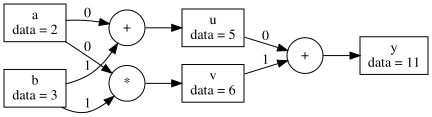

z = u * u: cùng một đỉnh ở hai vị trí đầu vào


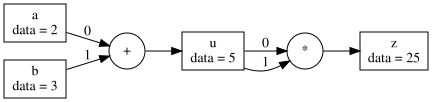

In [37]:
a = Value(2, label="a")
b = Value(3, label="b")

u = a + b
u.label = "u"

v = a * b
v.label = "v"

y = u + v
y.label = "y"

print("y = (a + b) + a * b")
graph_y = show_graph(y)

z = u * u
z.label = "z"

print("z = u * u: cùng một đỉnh ở hai vị trí đầu vào")
graph_z = show_graph(z)

# CÂU 3: TRUYỀN NGƯỢC
## 3.1 Tính đạo hàm tại một đỉnh
Đọc 2.3.1 trong file pdf đi kèm.

Trong class `Value`, hoàn thành method:
```python
def _backward(self):
  ```
Không thay đổi nội dung test, chạy `test_local_backward()` để kiểm tra.


In [41]:
def test_local_backward():
    print("Test 3.1: Truyền ngược một bước")

    try:
        print("\nNhân với gradient nhận được")
        a, b = Value(2), Value(3)
        u = a * b

        u.grad = 4
        u._backward()

        assert_close(a.grad, 12, "a.grad")
        assert_close(b.grad, 8, "b.grad")
        assert_close(u.grad, 4, "u.grad không đổi")

        print("\nCộng dồn vào gradient đã có")
        u._backward()

        assert_close(a.grad, 24, "a.grad")
        assert_close(b.grad, 16, "b.grad")

        print("\nCùng một object ở hai vị trí đầu vào")
        a = Value(3)
        u = a * a

        u.grad = 2
        u._backward()

        assert_close(a.grad, 12, "a.grad")

        print("\nChỉ truyền một bước, không tự duyệt toàn graph")
        a, b = Value(2), Value(3)
        u = a * b
        y = u + a

        y.grad = 2
        y._backward()

        assert_close(u.grad, 2, "u.grad")
        assert_close(a.grad, 2, "a.grad")
        assert_close(b.grad, 0, "b.grad")

        print("\nĐỉnh không có input")
        a = Value(2)
        a.grad = 5
        a._backward()

        assert_close(a.grad, 5, "a.grad không đổi")

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 3.1")
        return False

    print("\nPASS test 3.1")
    return True


test_local_backward();

Test 3.1: Truyền ngược một bước

Nhân với gradient nhận được
  a.grad: nhận 12.0, kì vọng 12
  b.grad: nhận 8.0, kì vọng 8
  u.grad không đổi: nhận 4, kì vọng 4

Cộng dồn vào gradient đã có
  a.grad: nhận 24.0, kì vọng 24
  b.grad: nhận 16.0, kì vọng 16

Cùng một object ở hai vị trí đầu vào
  a.grad: nhận 12.0, kì vọng 12

Chỉ truyền một bước, không tự duyệt toàn graph
  u.grad: nhận 2.0, kì vọng 2
  a.grad: nhận 2.0, kì vọng 2
  b.grad: nhận 0.0, kì vọng 0

Đỉnh không có input
  a.grad không đổi: nhận 5, kì vọng 5

PASS test 3.1


## 3.2 Thứ tự topo
Đọc file pdf mục 2.3.2. Hoàn thành hàm trong cell dưới đây:

**VIẾT MÃ VÀO CELL DƯỚI**

In [38]:
def build_topology(node, visited, order):
    pass

**KHÔNG SỬA ĐỔI CELL DƯỚI ĐÂY**

In [39]:
def topological_order(output):
    visited = set()
    order = []
    build_topology(output, visited, order)
    return order

Không thay đổi nội dung test, chạy `test_topology()` để kiểm tra.

In [43]:
def test_topology():
    print("Test 3.2: Thứ tự topo")

    try:
        a = Value(2, label="a")
        b = Value(2, label="b")

        u = a + b
        u.label = "u"

        v = a * b
        v.label = "v"

        y = u + v
        y.label = "y"

        z = u * u
        z.label = "z"

        unused = a - b
        unused.label = "unused"

        cases = [
            ("Một node riêng lẻ", a, {a}),
            ("Hai nhánh dùng chung đầu vào", y, {a, b, u, v, y}),
            ("Một object ở hai vị trí đầu vào", z, {a, b, u, z}),
        ]

        for description, output, expected_nodes in cases:
            print(f"\n{description}")
            order = topological_order(output)

            assert isinstance(order, list), "Kết quả phải là list"
            assert len(order) == len(set(order)), "Không được lặp node"
            assert set(order) == expected_nodes, (
                "Danh sách thiếu node hoặc chứa node ngoài graph"
            )
            print("  Đủ node, không lặp, không chứa unused: PASS")

            positions = {
                node: index for index, node in enumerate(order)
            }

            for node in order:
                for parent in node.parents:
                    assert positions[parent] < positions[node], (
                        f"Đầu vào {parent.label!r} phải đứng trước "
                        f"node {node.label!r}"
                    )

            print("  Mọi đầu vào đều đứng trước node sử dụng nó: PASS")
            print("  Thứ tự:", [node.label for node in order])

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 3.2")
        return False

    print("\nPASS test 3.2")
    return True


test_topology();

Test 3.2: Thứ tự topo

Một node riêng lẻ
  Đủ node, không lặp, không chứa unused: PASS
  Mọi đầu vào đều đứng trước node sử dụng nó: PASS
  Thứ tự: ['a']

Hai nhánh dùng chung đầu vào
  Đủ node, không lặp, không chứa unused: PASS
  Mọi đầu vào đều đứng trước node sử dụng nó: PASS
  Thứ tự: ['a', 'b', 'u', 'v', 'y']

Một object ở hai vị trí đầu vào
  Đủ node, không lặp, không chứa unused: PASS
  Mọi đầu vào đều đứng trước node sử dụng nó: PASS
  Thứ tự: ['a', 'b', 'u', 'z']

PASS test 3.2


## 3.3 Truyền ngược toàn đồ thị
Từ mục 1 và 2.3.3 trong file pdf, hãy hoàn thành method sau trong class `Value` để thực hiện `_backward()` trên toàn đồ thị:
```python
def backward(self):
```
Thứ tự duyệt sẽ là thứ tự topo đảo ngược. Mặc định các đỉnh đều có `grad` là 0.0, riêng `self.grad` là 1.0, do đạo hàm một biến theo chính nó là 1.

Không thay đổi nội dung test, chạy `test_backward()` để kiểm tra.

In [44]:
def test_backward():
    print("Test 3.3: Truyền ngược toàn đồ thị")

    try:
        print("\nVí dụ Hình 2: y = (a + b) + a * b")
        a = Value(2, label="a")
        b = Value(3, label="b")
        u = a + b
        v = a * b
        y = u + v

        y.backward()

        assert_close(y.grad, 1, "y.grad")
        assert_close(u.grad, 1, "u.grad")
        assert_close(v.grad, 1, "v.grad")
        assert_close(a.grad, 4, "a.grad")
        assert_close(b.grad, 3, "b.grad")

        print("\nĐặt lại gradient khi gọi backward lần nữa")
        for node in (a, b, u, v, y):
            node.grad = 100

        y.backward()

        assert_close(y.grad, 1, "y.grad")
        assert_close(u.grad, 1, "u.grad")
        assert_close(v.grad, 1, "v.grad")
        assert_close(a.grad, 4, "a.grad")
        assert_close(b.grad, 3, "b.grad")

        print("\nNode trung gian phải nhận đủ gradient trước khi truyền tiếp")
        a = Value(2)
        b = Value(3)
        u = a * b
        v = u * 2
        y = u + v

        y.backward()

        assert_close(y.data, 18, "y.data")
        assert_close(u.grad, 3, "u.grad")
        assert_close(a.grad, 9, "a.grad")
        assert_close(b.grad, 6, "b.grad")

        print("\nCùng một object ở hai vị trí đầu vào: y = u * u")
        a = Value(2)
        b = Value(3)
        u = a + b
        y = u * u

        y.backward()

        assert_close(y.data, 25, "y.data")
        assert_close(u.grad, 10, "u.grad")
        assert_close(a.grad, 10, "a.grad")
        assert_close(b.grad, 10, "b.grad")

        print("\nKhông thay đổi gradient của node ngoài graph")
        a = Value(2)
        b = Value(3)
        y = a + b
        unused = a * b
        unused.grad = 7

        y.backward()

        assert_close(a.grad, 1, "a.grad")
        assert_close(b.grad, 1, "b.grad")
        assert_close(unused.grad, 7, "unused.grad không đổi")

        print("\nĐầu ra là một node riêng lẻ")
        a = Value(2)
        a.grad = 100
        a.backward()

        assert_close(a.grad, 1, "a.grad")

    except Exception as error:
        print(f"\n{type(error).__name__}: {error}")
        print("FAIL test 3.3")
        return False

    print("\nPASS test 3.3")
    return True


test_backward();

Test 3.3: Truyền ngược toàn đồ thị

Ví dụ Hình 2: y = (a + b) + a * b
  y.grad: nhận 1.0, kì vọng 1
  u.grad: nhận 1.0, kì vọng 1
  v.grad: nhận 1.0, kì vọng 1
  a.grad: nhận 4.0, kì vọng 4
  b.grad: nhận 3.0, kì vọng 3

Đặt lại gradient khi gọi backward lần nữa
  y.grad: nhận 1.0, kì vọng 1
  u.grad: nhận 1.0, kì vọng 1
  v.grad: nhận 1.0, kì vọng 1
  a.grad: nhận 4.0, kì vọng 4
  b.grad: nhận 3.0, kì vọng 3

Node trung gian phải nhận đủ gradient trước khi truyền tiếp
  y.data: nhận 18, kì vọng 18
  u.grad: nhận 3.0, kì vọng 3
  a.grad: nhận 9.0, kì vọng 9
  b.grad: nhận 6.0, kì vọng 6

Cùng một object ở hai vị trí đầu vào: y = u * u
  y.data: nhận 25, kì vọng 25
  u.grad: nhận 10.0, kì vọng 10
  a.grad: nhận 10.0, kì vọng 10
  b.grad: nhận 10.0, kì vọng 10

Không thay đổi gradient của node ngoài graph
  a.grad: nhận 1.0, kì vọng 1
  b.grad: nhận 1.0, kì vọng 1
  unused.grad không đổi: nhận 7, kì vọng 7

Đầu ra là một node riêng lẻ
  a.grad: nhận 1.0, kì vọng 1

PASS test 3.3
